# MTL for DNSSEC: Incremental Signing

This notebook provides a demonstration of the MTL incremental signing from a server's perspective. 

## 📋 Demo Outline

<div class="alert alert-block alert-info" style="border-left: 20px solid #a8a7a8; border-right: solid #a8a7a8; border-top: solid #a8a7a8; border-bottom: solid #a8a7a8; background-color: #f1f0f2; padding: 15px; margin-bottom: 10px; color: #000;">
<h3 style="margin-top: 0; color: #757475;">Background and Demo Configurations</h3>
<ul>
    <li>Incremental Signing</li>
    <li>Importing Libraries</li>
    <li>Demo Configuration
        <ul>
            <li>Node Set</li>
            <li>Signing and Hashing Configurations</li>
        </ul>
    </li>
</ul>
</div>

<div class="alert alert-block alert-danger" style="border-left: 20px solid #c7745d; border-right: solid #c7745d; border-top: solid #c7745d; border-bottom: solid #c7745d; background-color: #f7f1ef; padding: 15px; margin-bottom: 10px; color: #000;">
<h3 style="margin-top: 0; color: #c97058;">Adding a New Leaf Node</h3>
<ul>
    <li><strong>Section 1</strong> The Ladder Before Updating</li>
    <li><strong>Section 2</strong> Generating a New Leaf Node</li>
        <ul>
            <li><strong>Section 2.1</strong> Adding A New Message</li>
            <li><strong>Section 2.2</strong> Calculating the New Leaf Node Hash</li>
            <li><strong>Section 2.3</strong> Updating the Node Set</li>
        </ul>
</ul>
</div>

<div class="alert alert-block alert-danger" style="border-left: 20px solid #d4ba4a; border-right: solid #d4ba4a; border-top: solid #d4ba4a; border-bottom: solid #d4ba4a; background-color: #fcfbf2; padding: 15px; margin-bottom: 10px; color: #000;">
<h3 style="margin-top: 0; color: #c4a519;">Updating MTL</h3>
<ul>
    <li><strong>Section 3</strong> Updating Rungs and the MTL Structure
        <ul>
            <li><strong>Section 3.1</strong> Calculating the Target Rung</li>
            <li><strong>Section 3.2</strong> All Rungs in the Updated Ladder</li>
            <li><strong>Section 3.3</strong> Updating MTL Structure</li>
        </ul>
    <li><strong>Section 4</strong> Updating the Ladder
    </li>
</ul>
</div>

<div class="alert alert-block alert-success" style="border-left: 20px solid #5c86a8; border-right: solid #5c86a8; border-top: solid #5c86a8; border-bottom: solid #5c86a8; background-color: #f5f9fc; padding: 15px; margin-bottom: 10px; color: #000;">
<h3 style="margin-top: 0; color: #4e7da3;">Updating Ladder Signature</h3>
<ul>
    <li><strong>Section 5</strong> Signing the Ladder
        <ul>
            <li><strong>Section 5.1</strong> Constructing the Ladder in Bytes</li>
            <li><strong>Section 5.2</strong> Generating the Ladder Signature</li>
            <li><strong>Section 5.3</strong> Generating the Signed Ladder</li>
        </ul> 
    </li>
</ul>
</div>

<div class="alert alert-block alert-danger" style="border-left: 20px solid #739e51; border-right: solid #739e51; border-top: solid #739e51; border-bottom: solid #739e51; background-color: #f6fcf2; padding: 15px; margin-bottom: 10px; color: #000;">
<h3 style="margin-top: 0; color: #5d8043;">Building Authentication Path</h3>
<ul>
    <li><strong>Section 6</strong> Building the Authentication Path</li>
        <ul>
            <li><strong>Section 6.1</strong> Obtaining Siblings of the Newly Added Leaf Node</li>
            <li><strong>Section 6.2</strong> Constructing the Authentication Path in Bytes</li>
        </ul>
</ul>
</div>

<div class="alert alert-block alert-warning" style="border-left: 20px solid #87779c; border-right: solid #87779c; border-top: solid #87779c; border-bottom: solid #87779c; background-color: #f9f7fc; padding: 15px; margin-bottom: 10px; color: #000;">
<h3 style="margin-top: 0; color: #6f5f82;">Constructing a Full Signature</h3>
<ul>
    <li><strong>Section 7</strong> Constructing the Full Signature</li>
</ul>
</div>

<div class="alert alert-block alert-danger" style="border-left: 20px solid #a8a7a8; border-right: solid #a8a7a8; border-top: solid #a8a7a8; border-bottom: solid #a8a7a8; background-color: #f1f0f2; padding: 15px; margin-bottom: 10px; color: #000;">
<h3 style="margin-top: 0; color: #757475;">Demo Summary</h3>
<ul>
    <li>End of Demo</li>
</ul>
</div>

## 📖 Incremental Signing
> One of the primary advantages of MTL is its ability to support efficient incremental signing for evolving message streams without requiring complete tree recalculations. MTL maintains a dynamic "node set" where new messages are sequentially appended as leaves. Because the node set is partitioned into complete binary trees, adding new nodes only requires new rungs to be added, or existing rungs to be combined, leaving the majority of the node set structure untouched. When new messages are added, new leaf nodes are added to the node set and the ladder signature is updated. Because the underlying signature is applied only to these evolving rungs rather than individual messages, new entries can be added continuously. Verifiers can then use compact Merkle proofs to validate individual messages against cached or newly retrieved ladders, mitigating heavy PQC signature costs over an expanding data stream. 

## 📦 Importing Libraries to Run This Demo

In [1]:
from IPython.display import display
import socket
import secrets

## ⚙️ Demo Configurations

### (1) Node Set
This demo uses a pre-defined node set at `data/incrsig/nodeset.json`, which contains 10 leaf nodes. Section 1 provides further details about this node set. 

### (2) Signing and Hashing Configurations
The signature algorithm must match the public key and signature specified below, and the hash algorithm and security parameters must match the ladder configuration.

<div style="border-left: 5px solid #FFC107; background-color: #FFFDF5; padding: 12px; border-radius: 4px; color: #000;">
    <strong>⚠️ Please note:</strong> Field sizes in following sections depend on the signature algorithms and may vary if other algorithms are used, which requires corresponding modifications to the underlying functions. 
</div>

In [2]:
# ML-DSA signature algorithm (should be supported by OpenSSL version 3.5.0):
sig_alg = "ML-DSA-44"

# Hash algorithm for generating node hashes: this demo supports "shake".
hash_alg = "shake"

# Security parameter n: this demo supports n = 16, 24, or 32.
n = 16

## 1. The Ladder Before Updating

The ladder before updating is as follows:

In [3]:
from helper.mtl_parser import Ladder

with open("data/incrsig/prev_ladder.txt", "r") as f:
    readin_val = f.read()
readin_bytes = bytes.fromhex(readin_val)

ladder = Ladder(fullsig=readin_bytes, n=n)
display(ladder.ladder_print())

Ladder Field,Field Length (bytes),Field Data


The ladder structure can be visualized as follows:

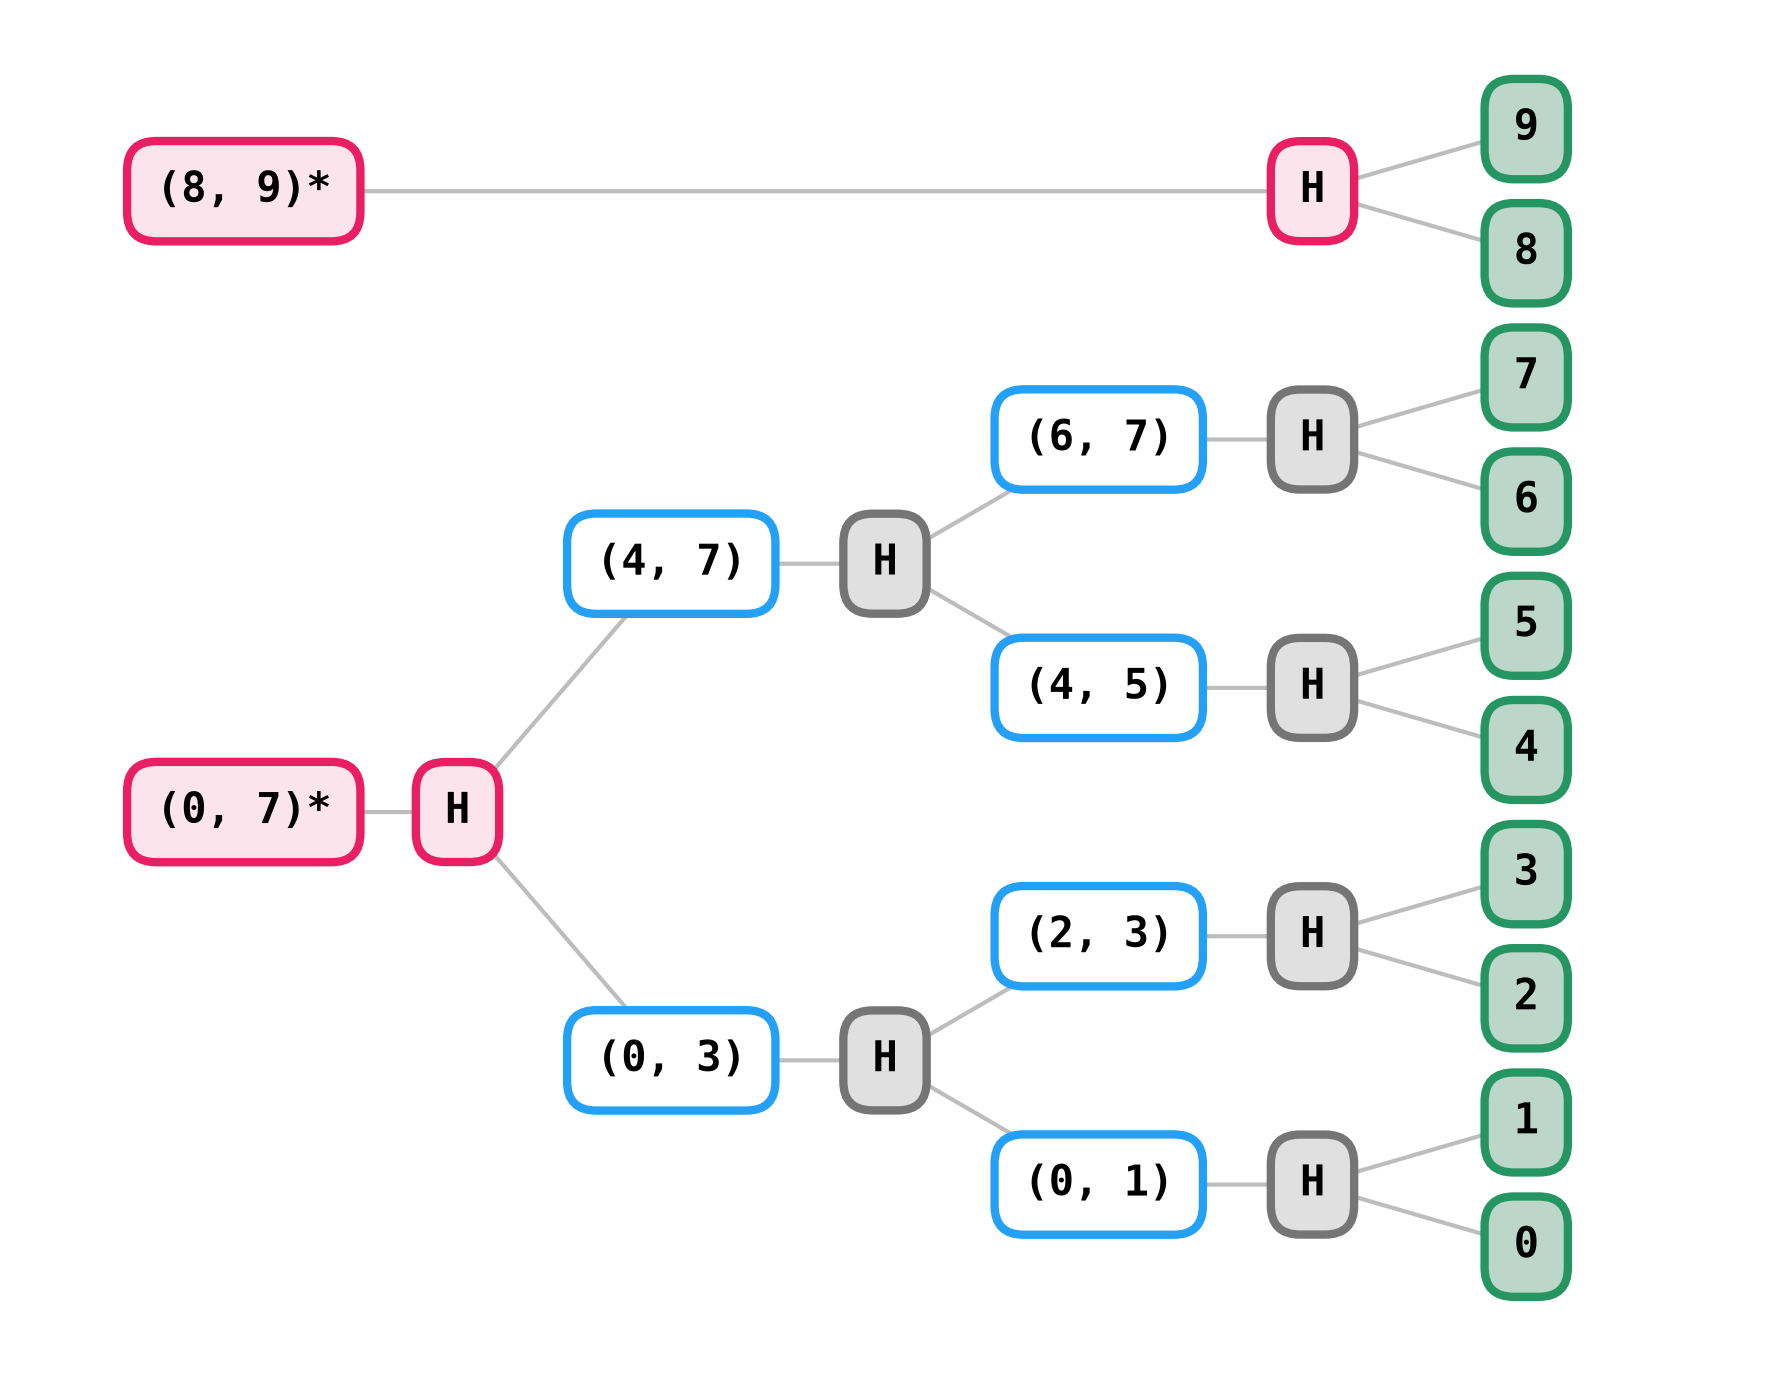

In [4]:
from helper.utils import calculate_total_leaves, mtl_print
%config InlineBackend.figure_format = 'retina'

total_leaves = calculate_total_leaves(ladder.rungs)
ladder.total_leaves = total_leaves
mtl_print(ladder.total_leaves, ladder.rungs, target_width=6)

## 2. Generating A New Leaf Node

### 2.1 Adding A New Message

Assume we are adding the following DNSSEC message as a new leaf node:

In [5]:
# RRSIG RDATA 
rrsig_meta = {
    "type_covered": 28,                                # DNS record type AAAA
    "algorithm": 131,                                  # Assumed algorithm ID
    "labels": 2,                                       # "ns1.example." has two labels
    "original_ttl": 3600,                              # The TTL the signature is based on
    "sig_expiration": 20260203132321,                  # Signature expiration timestamp
    "sig_inception": 20260106132321,                   # Signature inception timestamp
    "key_tag": 46491,                                  # ID of the DNSKEY used for signing
    "signer_name": "example."                          # Signer's name
}

# RRset Data
rrset = [
    {
        "name": "ns1.example.", 
        "type": 28, 
        "class": 1, 
        "rdata": socket.inet_pton(socket.AF_INET6, "2001:db8:85a3::8a2e:370:7334")
    },
]

We call the helper to concatenate the RRSIG RDATA (excluding the signature field) with the canonicalized RRset to create the signed data:

In [6]:
from helper.utils import create_dnssec_signed_data, print_data

message = create_dnssec_signed_data(rrsig_meta, rrset)
print_data("DNSSEC Signed Data", message.hex(), len(message))

╭─────────────────────────── DNSSEC Signed Data ────────────────────────────╮
│                                                                           │
│  001C8302 00000E10 6981F6C9 695D0CC9 B59B0765 78616D70 6C650003 6E733107  │
│  6578616D 706C6500 001C0001 00000E10 00102001 0DB885A3 00000000 8A2E0370  │
│  7334                                                                     │
│                                                                           │
│                                                                           │
│  Length of DNSSEC Signed Data: 66 bytes                                   │
│                                                                           │
╰───────────────────────────────────────────────────────────────────────────╯

The signed data shown above is the messsage that the new leaf node carries. 

In [7]:
from helper.ladder_updater import LeafNode
leaf_node = LeafNode(lindex=ladder.total_leaves, rindex=ladder.total_leaves)
leaf_node.message = message

### 2.2 Calculating the New Leaf Node Hash

To calculate the hash value of this message, we first need to generate a randomizer that is associated to this leaf node: 

In [8]:
leaf_node.randomizer = secrets.token_bytes(16)
print_data("Randomizer", leaf_node.randomizer.hex(), len(leaf_node.randomizer))

╭───────────── Randomizer ──────────────╮
│                                       │
│  BE948CD4 62BD1B69 9657CE38 DA688BF5  │
│                                       │
│                                       │
│  Length of Randomizer: 16 bytes       │
│                                       │
╰───────────────────────────────────────╯

We next use this randomizer to generate the hash value of this newly added leaf node.

In [9]:
from helper.verifier import hash_leaf

# Leave the context string (ctx_msg) NULL
leaf_node.node_hash = hash_leaf(
                        sid=ladder.sid,
                        leaf_index=leaf_node.lindex,
                        randomizer=leaf_node.randomizer,
                        ctx_msg=b"",
                        message=message,
                        hash_alg=hash_alg,
                        n=n
)
display(leaf_node.leaf_print())

"Leaf Node (10, 10)",Value


### 2.3 Updating the Node Set

We call the helper function to add this new leaf node to the node set and update internal nodes when two child nodes merge to create a new parent node. 

In [10]:
from helper.ladder_updater import update_nodeset

updated_nodeset = update_nodeset(nodeset_filepath="data/incrsig/nodeset.json", 
                                 updated_nodeset_path="data/incrsig/updated_nodeset.json",
                                 hash_alg=hash_alg, 
                                 n=n, 
                                 node_rand=leaf_node.randomizer,
                                 node_hash=leaf_node.node_hash)

The Node Set has been updated and saved.


## 3. Updating Rungs and the MTL structure

### 3.1 Calculating the Target Rung

In [11]:
from helper.ladder_updater import find_target_rung

target_rung = find_target_rung(nodeset=updated_nodeset, leaf_index=leaf_node.lindex)

leaf_node.rung_lindex_int = target_rung["left_index"]
leaf_node.rung_rindex_int = target_rung["right_index"]
leaf_node.rung_lindex = leaf_node.rung_lindex_int.to_bytes(8, byteorder="big")
leaf_node.rung_rindex = leaf_node.rung_rindex_int.to_bytes(8, byteorder="big")
leaf_node.rung_hash = bytes.fromhex(target_rung["hash"])

(leaf_node.targetrung_print())

"Leaf Node (10, 10) Target Rung",Value


### 3.2 All Rungs in the Updated Ladder

The updated ladder will have the following rungs: 

In [12]:
from helper.ladder_updater import get_all_rungs, allrungs_print

rungs_list = get_all_rungs(nodeset=updated_nodeset)
display(allrungs_print(rungs_list))

Field,Field Length (bytes),Field Data


### 3.3 Updating MTL Structure

The updated ladder will have the following structure:  

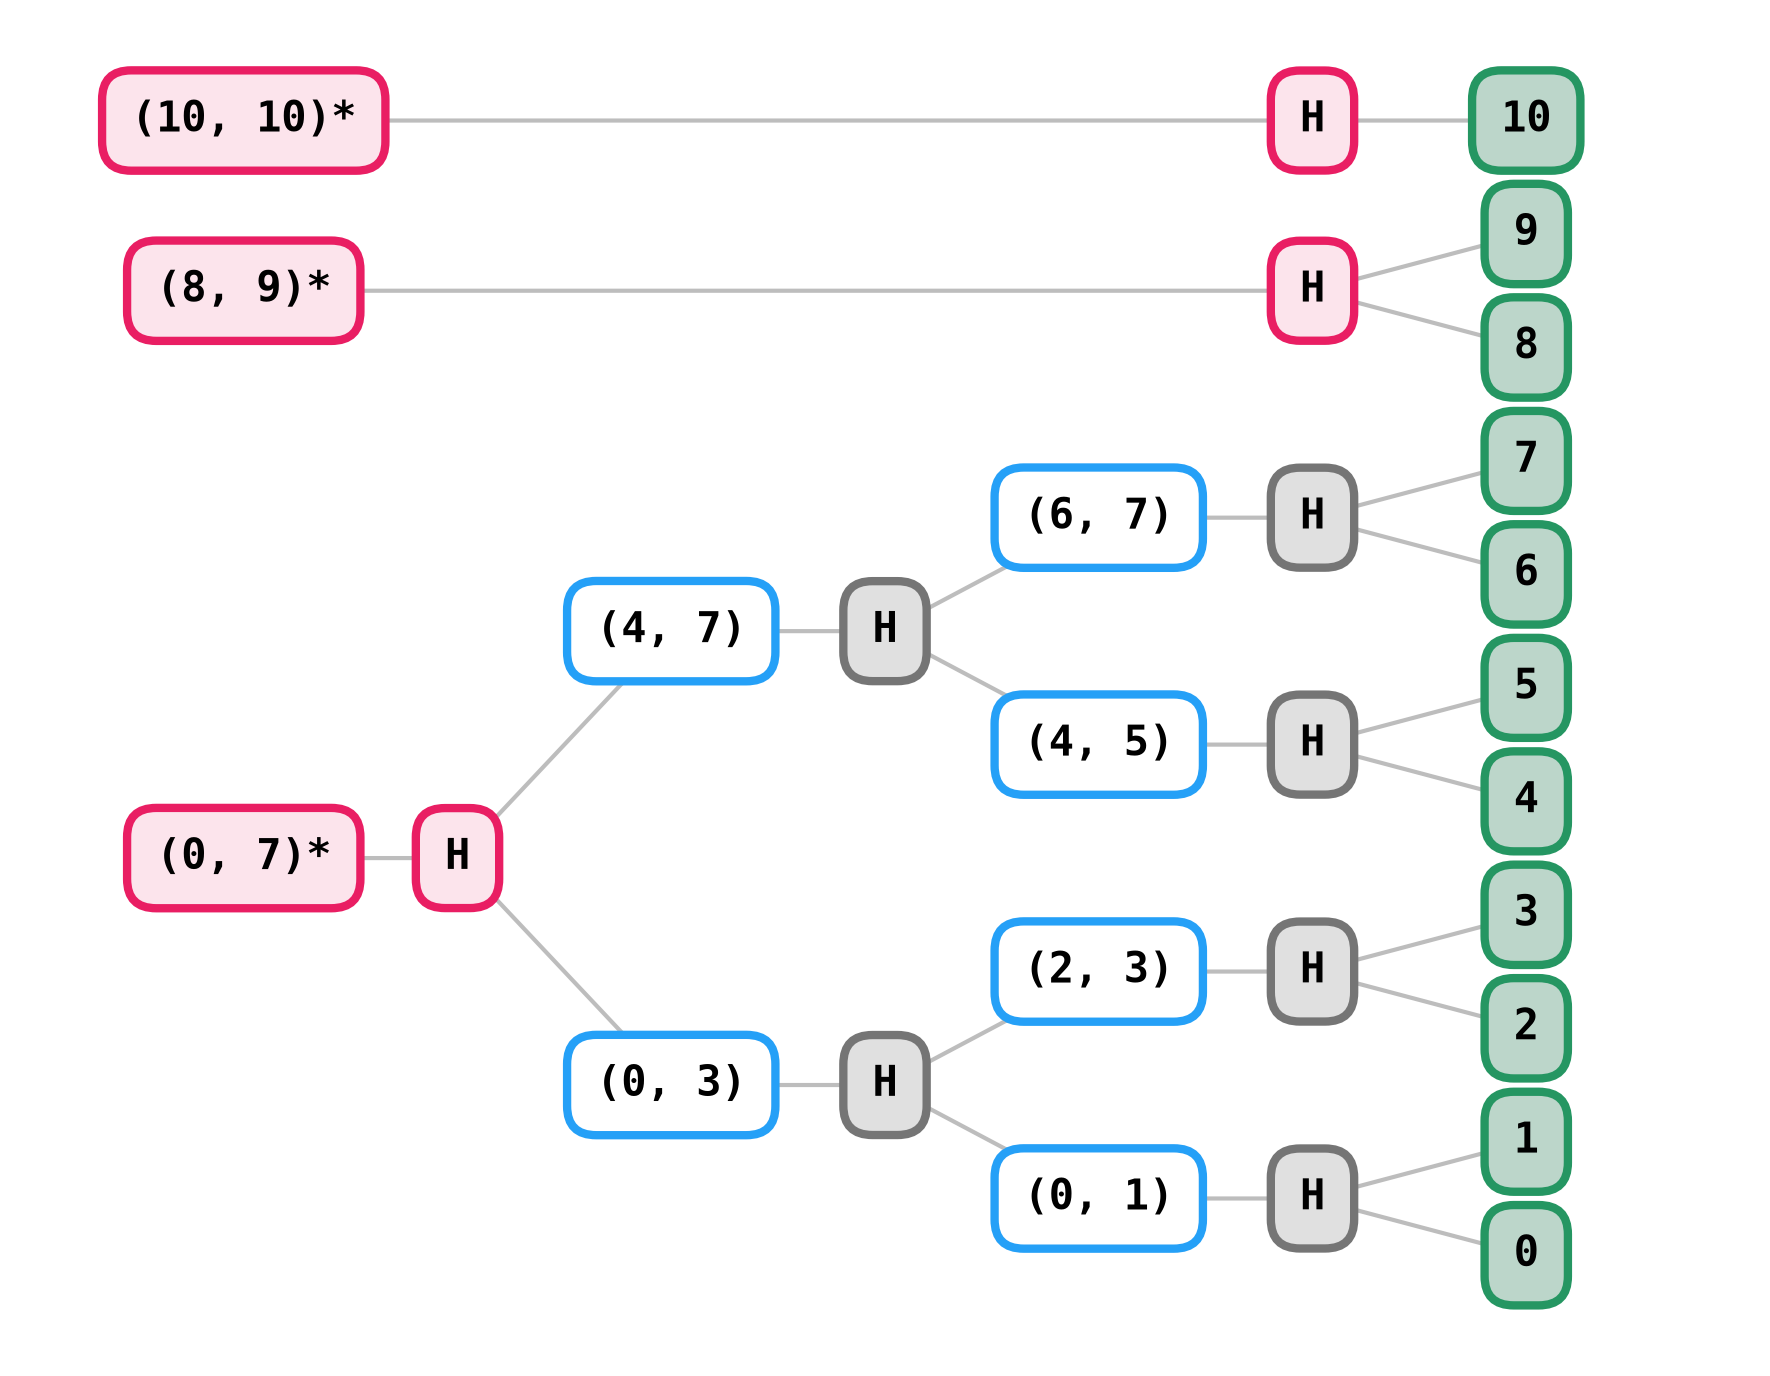

In [13]:
from helper.utils import calculate_total_leaves, mtl_print

total_leaves = calculate_total_leaves(rungs_list)
mtl_print(total_leaves, rungs_list, target_width=6)

## 4. Updating the Ladder

We update the ladder based on rungs obtained earlier, as follows:

In [14]:
ladder.rung_cnt = len(rungs_list)
ladder.rungs = []

for rung in rungs_list:
    ladder.rungs.append({
        "left_index": rung["left_index"],
        "right_index": rung["right_index"],
        "left_index_int": rung["left_index_int"],
        "right_index_int": rung["right_index_int"],
        "hash": bytes.fromhex(rung["hash"])
    })
ladder.total_leaves = leaf_node.lindex + 1
display(ladder.ladder_print())

Ladder Field,Field Length (bytes),Field Data


## 5. Signing the Ladder

A signed ladder data structure consists of:

```
                     1 1 1 1 1 1
 0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5
+-------------------------------+
|             Flag              |
+-------------------------------+
|                               |
//             SID             //
|                               |
+-------------------------------+
|           Rung Count          |
+-------------------------------+
|                               |
//          Rung Data          //
|                               |
+-------------------------------+
|  Underlying Signature Length  |
|                               |
+-------------------------------+
|                               |
//     Underlying Signature    //
|                               |
+-------------------------------+
```

### 5.1 Constructing the Ladder in Bytes

In [15]:
ladder.val = ladder.flag + \
             ladder.sid + \
             ladder.rung_cnt.to_bytes(2, byteorder="big")

for each_rung in ladder.rungs:
    ladder.val += each_rung["left_index"] + each_rung["right_index"] + each_rung["hash"]

with open("data/incrsig/updated_ladder.txt", "w") as file:
    file.write(ladder.val.hex())

print_data("Updated Ladder", ladder.val.hex(), len(ladder.val), n=n, print_type="ladder")

┌────────────────────────────────────────────────────────────────────────────┐
│  ■ Flags           ■ SID              ■ Rung Count      ■ Rung [1] Index   │
│  ■ Rung [1] Hash   ■ Rung [2] Index   ■ Rung [2] Hash   ■ Rung [3] Index   │
│  ■ Rung [3] Hash                                                           │
└────────────────────────────────────────────────────────────────────────────┘

╭───────────────────────────── Updated Ladder ──────────────────────────────╮
│                                                                           │
│  00008F5C E818A1DF 091DFB82 88CCAD6F F45099A4 8C464F54 0CAB0511 4981736B  │
│  B9D00003 00000000 00000000 00000000 00000007 79A2EE20 A2778083 CBF9731E  │
│  F165D3FC 00000000 00000008 00000000 00000009 F7BD25C0 259AEE46 30C78B9E  │
│  54B2704B 00000000 0000000A 00000000 0000000A 8084FF93 EEE46B32 1B35102C  │
│  0A84290C                                                                 │
│                                                                           │
│                                                                           │
│  Length of Updated Ladder: 132 bytes                                      │
│                                                                           │
╰───────────────────────────────────────────────────────────────────────────╯

### 5.2 Generating the Ladder Signature

We call helper functions to generate an ML-DSA key pair and sign the ladder using the private key. (Note that, in practice, this private key would not change across additions to the node set.)

In [16]:
from helper.signer import generate_ml_dsa_keypair, export_public_key

mldsa_keypair = generate_ml_dsa_keypair(sig_alg)
mldsa_pubkey = export_public_key(mldsa_keypair)

hex_pubkey = mldsa_pubkey.hex()
with open("data/incrsig/incrsig_pubkey.txt", "w") as file:
    file.write(hex_pubkey)

Generating key pair for ML-DSA-44...
Successfully generated ML-DSA key pair.


In [17]:
from helper.signer import sign_message

signature = sign_message(mldsa_keypair, sig_alg, ladder.val)
sig_hex = signature.hex()
with open("data/incrsig/incrsig_sigature.txt", "w") as file:
    file.write(sig_hex)

Successfully created ML-DSA signature.


### 5.3 Generating the Signed Ladder

We construct the signed ladder by concatenating the ladder, the signature length, and the signature, as follows: 

In [18]:
ladder.sig_len = len(signature).to_bytes(4, byteorder="big")
ladder.signature = signature

signed_ladder = ladder.val + ladder.sig_len + ladder.signature

with open("data/incrsig/incrsig_signedladder.txt", "w") as file:
    file.write(signed_ladder.hex())  
print_data("Signed Ladder", signed_ladder.hex(), len(signed_ladder), n=n, print_type="signed_ladder")

┌──────────────────────────────────────────────────────────────────────────────┐
│  ■ Flags           ■ SID                ■ Rung Count      ■ Rung [1] Index   │
│  ■ Rung [1] Hash   ■ Rung [2] Index     ■ Rung [2] Hash   ■ Rung [3] Index   │
│  ■ Rung [3] Hash   ■ Signature Length   ■ Signature                          │
└──────────────────────────────────────────────────────────────────────────────┘

╭────────────────────────────── Signed Ladder ──────────────────────────────╮
│                                                                           │
│  00008F5C E818A1DF 091DFB82 88CCAD6F F45099A4 8C464F54 0CAB0511 4981736B  │
│  B9D00003 00000000 00000000 00000000 00000007 79A2EE20 A2778083 CBF9731E  │
│  F165D3FC 00000000 00000008 00000000 00000009 F7BD25C0 259AEE46 30C78B9E  │
│  54B2704B 00000000 0000000A 00000000 0000000A 8084FF93 EEE46B32 1B35102C  │
│  0A84290C 00000974 29B0170A B21A23A5 31DA5F87 B4C27A0A AC170009 BA32ABB8  │
│  E5A935F3 D06578D5 35884DBF 90A087DD 72C8B0AF 9758C650 BAC9C2A1 919213AB  │
│  3FADDD4D 6B8426BE 3CE1A869 50DF0B6D D08F6377 BDBECCD0 C29EEC1D 0C272318  │
│  4B28CF1A C5F444F1 9561BEE9 6AE13E4C FC2923D2 BC3F37F1 290A466B 5CB77AD3  │
│  3CFE1015 C150A752 AA539DDE 95EC04C2 155FFD2F 97156A2A 148D0C74 9751B5E0  │
│  9CAD1B58 D5CD1759 10193664 9219DDB6 BB3309CB 6EA12CE2 DDB1D2C3 EB2B4E3D  │
│  BED03B84 75EFF07E 0BF77AED D2B64EA3 840DA5D5 7DDB8D54 5AAEDB3A 60EFB323  │
│  5E0279E4 846EABCF 2F55E65D F8F905C6 668C8269 C4AF11D7 77668135 97FECE32  │
│  5BA8E268 E9F20691 87F43AC0 ADC9918F 227CC8E8 90708711 10C7266F 191882A2  │
│  EC4B4116 0A7B6EBC 0FF3FCF8 91AEE038 81686A1E 24799AA2 3EC8A85B 4067DEE9  │
│  82D56267 798B75BE FD23B00E 2BCD70F0 2E4C1D4D 53DCD1AA 82C2115B F1C714E1  │
│  3ED0BC1E 10810226 3C299671 895F69CA 110FFFEB 635F46CC 1A0A5246 ABE32FE8  │
│  1F85716D 1C96A395 0984AAEB E6953DDD B86F00E6 B48EBE51 A4532B94 B7B3EDB1  │
│  D7685F2A 3DC33691 BBFB3F55 62B4E7BB ED1F260D BAD58053 C48C6526 3154A5E0  │
│  79BE4245 8355FBC1 2BA2ED40 8F43CDC5 89E3BFB8 DE43BB81 04F67AC1 62B4DA91  │
│  2BD4A12B B1BA2C5B 8BED391E 4EEA4D3F 6B67B953 C77ED613 C0D33812 EA2C66A8  │
│  250CE2CE 96CB35EA 747087AD EB564653 2F64836A 6016497F 53592671 323EBEE5  │
│  5BDA5E43 31D117DA C4CD24EA DCD2BAA6 521D0EC3 [1;38;2;180;181;181;48;2;255;

## 6. Building the Authentication Path

We now need to generate the authentication path for this newly added leaf node. An authentication path consists of the following components: 

```
                     1 1 1 1 1 1
 0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5
+-------------------------------+
|             Flags             |
+-------------------------------+
|                               |
//             SID             //
|                               |
+-------------------------------+
|                               |
//          Randomizer         //
|                               |
+-------------------------------+
|                               |
|           Leaf Index          |
|                               |
|                               |
+-------------------------------+
|                               |
|     Target Rung Left Index    |
|                               |
|                               |
+-------------------------------+
|                               |
|    Target Rung Right Index    |
|                               |
|                               |
+-------------------------------+
|       Sibling Hash Count      |
+-------------------------------+
|                               |
//      Sibling Hash Values    //
|                               |
+-------------------------------+
```

### 6.1 Obtaining Siblings of the Newly Added Leaf Node

In [19]:
from helper.ladder_updater import get_sibling_nodes

sibling_list = get_sibling_nodes(nodeset=updated_nodeset, leaf_index=leaf_node.lindex)

leaf_node.siblings = []
leaf_node.siblings_withindex = []

if not sibling_list:
    print(f"\033[1;31mThe Leaf Node ({leaf_node.lindex}, {leaf_node.rindex}) does not have siblings\033[0m.")
else: 
    for idx, sib in enumerate(sibling_list):
        leaf_node.siblings.append(bytes.fromhex(sib["hash"]))
        leaf_node.siblings_withindex.append({
            "left_index": sib["left_index"],
            "right_index": sib["right_index"],
            "hash": bytes.fromhex(sib["hash"])
        })
    
    display(leaf_node.leafsiblings_print())

The Leaf Node (10, 10) does not have siblings.


### 6.2 Constructing the Authentication Path in Bytes

In [20]:
# Flag has to be 0
authpath_bytes = int("0").to_bytes(2, byteorder="big") + \
                 ladder.sid + \
                 leaf_node.randomizer + \
                 leaf_node.lindex.to_bytes(8, byteorder="big") + \
                 leaf_node.rung_lindex + \
                 leaf_node.rung_rindex + \
                 len(leaf_node.siblings).to_bytes(2, byteorder="big")

if leaf_node.siblings:
    for each_sib_hash in leaf_node.siblings:
        authpath_bytes += each_sib_hash

leaf_node.authpath = authpath_bytes
display(leaf_node.authpath_print())

"Leaf Node (10, 10) Authentication Path",Value


## 7. Constructing the Full Signature

The full signature should start with the `MTL-Type` of 1, as specified in draft-kaizer-dnsop-ml-dsa-mtl-dnssec-03, followed by components listed below:
```
                     1 1 1 1 1 1
 0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5
+-------------------------------+
|                               |
//     Condensed Signature     //
|     (Authentication Path)     |
+-------------------------------+
|                               |
//        Signed Ladder        //
|                               |
+-------------------------------+
```

In [21]:
full_sig = int(1).to_bytes(1, byteorder="big") + leaf_node.authpath + signed_ladder

with open("data/incrsig/incrsig_fullsig.txt", "w") as file:
    file.write(full_sig.hex())
print_data("Full Signature", full_sig.hex(), len(full_sig), n=n, print_type="fullsig")

┌──────────────────────────────────────────────────────────────────────────────────────┐
│  ■ MTL-Type           ■ Flags               ■ SID                  ■ Randomizer      │
│  ■ Leaf Index         ■ Target Rung Index   ■ Sibling Hash Count   ■ Flags           │
│  ■ SID                ■ Rung Count          ■ Rung [1] Index       ■ Rung [1] Hash   │
│  ■ Rung [2] Index     ■ Rung [2] Hash       ■ Rung [3] Index       ■ Rung [3] Hash   │
│  ■ Signature Length   ■ Signature                                                    │
└──────────────────────────────────────────────────────────────────────────────────────┘

╭───────────────────────────── Full Signature ──────────────────────────────╮
│                                                                           │
│  0100008F 5CE818A1 DF091DFB 8288CCAD 6FF45099 A48C464F 540CAB05 11498173  │
│  6BB9D0BE 948CD462 BD1B6996 57CE38DA 688BF500 00000000 00000A00 00000000  │
│  00000A00 00000000 00000A00 0000008F 5CE818A1 DF091DFB 8288CCAD 6FF45099  │
│  A48C464F 540CAB05 11498173 6BB9D000 03000000 00000000 00000000 00000000  │
│  0779A2EE 20A27780 83CBF973 1EF165D3 FC000000 00000000 08000000 00000000  │
│  09F7BD25 C0259AEE 4630C78B 9E54B270 4B000000 00000000 0A000000 00000000  │
│  0A8084FF 93EEE46B 321B3510 2C0A8429 0C000009 7429B017 0AB21A23 A531DA5F  │
│  87B4C27A 0AAC1700 09BA32AB B8E5A935 F3D06578 D535884D BF90A087 DD72C8B0  │
│  AF9758C6 50BAC9C2 A1919213 AB3FADDD 4D6B8426 BE3CE1A8 6950DF0B 6DD08F63  │
│  77BDBECC D0C29EEC 1D0C2723 184B28CF 1AC5F444 F19561BE E96AE13E 4CFC2923  │
│  D2BC3F37 F1290A46 6B5CB77A D33CFE10 15C150A7 52AA539D DE95EC04 C2155FFD  │
│  2F97156A 2A148D0C 749751B5 E09CAD1B 58D5CD17 59101936 649219DD B6BB3309  │
│  CB6EA12C E2DDB1D2 C3EB2B4E 3DBED03B 8475EFF0 7E0BF77A EDD2B64E A3840DA5  │
│  D57DDB8D 545AAEDB 3A60EFB3 235E0279 E4846EAB CF2F55E6 5DF8F905 C6668C82  │
│  69C4AF11 D7776681 3597FECE 325BA8E2 68E9F206 9187F43A C0ADC991 8F227CC8  │
│  E8907087 1110C726 6F191882 A2EC4B41 160A7B6E BC0FF3FC F891AEE0 3881686A  │
│  1E24799A A23EC8A8 5B4067DE E982D562 67798B75 BEFD23B0 0E2BCD70 F02E4C1D  │
│  4D53DCD1 AA82C211 5BF1C714 E13ED0BC 1E108102 263C2996 71895F69 CA110FFF  │
│  EB635F46 CC1A0A52 46ABE32F E81F8571 6D1C96A3 950984AA EBE6953D DDB86F00  │
│  E6B48EBE 51A4532B 94B7B3ED B1D7685F 2A3DC336 91BBFB3F 5562B4E7 BBED1F26  │
│  0DBAD580 53C48C65 263154A5 E079BE42 458355FB C12BA2ED 408F43CD C589E3BF  │
│[48;2;255;255;255

This full signature consists of the authentication path for the given leaf node and the signed ladder. The ladder can be verified using the` 2-verify_a_fullsig` notebook by replacing the public key and the full signature with the ones we obtained in this demo. 

## 📝 End of Demo

This demo walks through how a server performs incremental signing to an MTL, including:
  * Generating a new leaf node, 
  * Updating and signing the ladder,
  * Building the authentication path for the newly generated leaf node. 